<a href="https://colab.research.google.com/github/ChristZ-coderFs/ITC3154-Customer-Churn/blob/manthos-mlp/Standard_MLP_Architecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard MLP Architecture, Christos Zotos

In [ ]:
import torch
import torch.nn as nn
print(torch.__version__)

2.14.1+cpu


In [ ]:
model = nn.Sequential(
    nn.Linear(45, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
)

print(model)

Sequential(
  (0): Linear(in_features=45, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=1, bias=True)
)


In [ ]:
sample = torch.rand(1, 45)
output = model(sample)
print("Input shape:", sample.shape)
print("Output shape:", output.shape)
print("Model output:", output)

Input shape: torch.Size([1, 45])
Output shape: torch.Size([1, 1])
Model output: tensor([[0.0207]], grad_fn=<AddmmBackward0>)


In [33]:
parameters = sum(p.numel() for p in model.parameters()
                 if p.requires_grad)

print("Trainable parameters:", parameters)

Trainable parameters: 5057


# Standard MLP Architecture, Manthos Balouris

In [2]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("Environment ready!")

PyTorch version: 2.14.1+cpu
Environment ready!


In [5]:
train_df = pd.read_csv("churn_train.csv")
val_df = pd.read_csv("churn_validation.csv")
test_df = pd.read_csv("churn_test.csv")

print("Training dataset:", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (4930, 46)
Validation dataset: (1056, 46)
Testing dataset: (1057, 46)


# Dataset verification

In [6]:
for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(f"\n{name} dataset")
    print("Missing values:", df.isnull().sum().sum())
    print("Target labels:", sorted(df["Churn"].unique()))
    print("Numerical data:", all(
        pd.api.types.is_numeric_dtype(df[col])
        for col in df.columns
    ))

print("\nMatching columns:",
      train_df.columns.equals(val_df.columns)
      and train_df.columns.equals(test_df.columns))


Training dataset
Missing values: 0
Target labels: [np.int64(0), np.int64(1)]
Numerical data: True

Validation dataset
Missing values: 0
Target labels: [np.int64(0), np.int64(1)]
Numerical data: True

Testing dataset
Missing values: 0
Target labels: [np.int64(0), np.int64(1)]
Numerical data: True

Matching columns: True


# Separate Features and Target Labels

In [7]:


X_train = train_df.drop(columns=["Churn"])
y_train = train_df["Churn"]

X_val = val_df.drop(columns=["Churn"])
y_val = val_df["Churn"]

X_test = test_df.drop(columns=["Churn"])
y_test = test_df["Churn"]

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4930, 45)
y_train: (4930,)
X_val: (1056, 45)
y_val: (1056,)
X_test: (1057, 45)
y_test: (1057,)


# Convert Data into PyTorch Tensors

In [8]:

X_train_tensor = torch.tensor(X_train.values, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val.values, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test.values, dtype=torch.float32)


y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_val_tensor = torch.tensor(y_val.values, dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)


print("Training:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation:", X_val_tensor.shape, y_val_tensor.shape)
print("Testing:", X_test_tensor.shape, y_test_tensor.shape)

Training: torch.Size([4930, 45]) torch.Size([4930, 1])
Validation: torch.Size([1056, 45]) torch.Size([1056, 1])
Testing: torch.Size([1057, 45]) torch.Size([1057, 1])


# Create Datasets and DataLoaders

In [9]:
from torch.utils.data import TensorDataset, DataLoader


train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


BATCH_SIZE = 64


train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 78
Validation batches: 17
Testing batches: 17


# Import and Verify Standard MLP Architecture

In [14]:
import torch.nn as nn
import torch.optim as optim
import copy


christos_model = copy.deepcopy(model)

# Create an independent model for training
model = copy.deepcopy(christos_model)

# Verify the model with a training batch
sample_X, sample_y = next(iter(train_loader))

with torch.no_grad():
    output = model(sample_X)

print("\nBatch input shape:", sample_X.shape)
print("Model output shape:", output.shape)
print("Target shape:", sample_y.shape)

print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))


Batch input shape: torch.Size([64, 45])
Model output shape: torch.Size([64, 1])
Target shape: torch.Size([64, 1])
Trainable parameters: 5057


# Baseline Training Configuration

In [15]:

LEARNING_RATE = 0.001
MAX_EPOCHS = 100
PATIENCE = 10
THRESHOLD = 0.5


criterion = nn.BCEWithLogitsLoss()


optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Optimizer: Adam")
print("Loss function:", criterion)
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Classification threshold:", THRESHOLD)

Optimizer: Adam
Loss function: BCEWithLogitsLoss()
Learning rate: 0.001
Batch size: 64
Maximum epochs: 100
Early stopping patience: 10
Classification threshold: 0.5


# Random Seeds and Model Initialization

In [16]:
import random
import time


SEEDS = [42, 123, 456]


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


def create_model(seed):
    set_seed(seed)

    new_model = copy.deepcopy(christos_model)

    for layer in new_model.modules():
        if isinstance(layer, nn.Linear):
            layer.reset_parameters()

    return new_model

# Verify model initialization
model = create_model(SEEDS[0])

print("Training seeds:", SEEDS)
print("Model initialization successful!")

Training seeds: [42, 123, 456]
Model initialization successful!


# Training, Validation and Early Stopping

In [17]:
def train_model(seed, learning_rate=0.001, batch_size=64,
                max_epochs=100, patience=10):

    # Initialize a fresh model
    model = create_model(seed)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    # Create DataLoaders
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    epochs_without_improvement = 0

    start_time = time.time()

    for epoch in range(max_epochs):

        # Training phase
        model.train()
        running_train_loss = 0.0

        for X_batch, y_batch in train_loader:

            optimizer.zero_grad()

            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * X_batch.size(0)

        train_loss = running_train_loss / len(train_dataset)

        # Validation phase
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():

            for X_batch, y_batch in val_loader:

                outputs = model(X_batch)
                loss = criterion(outputs, y_batch)

                running_val_loss += loss.item() * X_batch.size(0)

        val_loss = running_val_loss / len(val_dataset)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Epoch {epoch + 1:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

        # Early stopping
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0

        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}")
            break

    # Restore the best model weights
    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    return {
        "model": model,
        "seed": seed,
        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_trained": len(train_losses),
        "training_time": training_time
    }

print("Training function ready!")

Training function ready!


# Baseline Model Training

In [18]:
# Train the baseline model using three random seeds
baseline_results = []

for seed in SEEDS:

    print(f"\n{'=' * 50}")
    print(f"Baseline training - Seed: {seed}")
    print(f"{'=' * 50}")

    result = train_model(
        seed=seed,
        learning_rate=LEARNING_RATE,
        batch_size=BATCH_SIZE,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE
    )

    baseline_results.append(result)

    print("\nTraining summary")
    print("Best epoch:", result["best_epoch"])
    print("Epochs trained:", result["epochs_trained"])
    print(f"Best validation loss: {result['best_val_loss']:.4f}")
    print(f"Training time: {result['training_time']:.2f} seconds")

print("\nAll baseline training runs completed!")


Baseline training - Seed: 42
Epoch 001 | Train Loss: 0.5204 | Val Loss: 0.4333
Epoch 002 | Train Loss: 0.4243 | Val Loss: 0.4238
Epoch 003 | Train Loss: 0.4214 | Val Loss: 0.4275
Epoch 004 | Train Loss: 0.4160 | Val Loss: 0.4283
Epoch 005 | Train Loss: 0.4175 | Val Loss: 0.4200
Epoch 006 | Train Loss: 0.4129 | Val Loss: 0.4218
Epoch 007 | Train Loss: 0.4130 | Val Loss: 0.4200
Epoch 008 | Train Loss: 0.4114 | Val Loss: 0.4181
Epoch 009 | Train Loss: 0.4088 | Val Loss: 0.4171
Epoch 010 | Train Loss: 0.4084 | Val Loss: 0.4205
Epoch 011 | Train Loss: 0.4094 | Val Loss: 0.4195
Epoch 012 | Train Loss: 0.4058 | Val Loss: 0.4204
Epoch 013 | Train Loss: 0.4050 | Val Loss: 0.4189
Epoch 014 | Train Loss: 0.4032 | Val Loss: 0.4228
Epoch 015 | Train Loss: 0.4013 | Val Loss: 0.4217
Epoch 016 | Train Loss: 0.4005 | Val Loss: 0.4220
Epoch 017 | Train Loss: 0.3972 | Val Loss: 0.4313
Epoch 018 | Train Loss: 0.3983 | Val Loss: 0.4264
Epoch 019 | Train Loss: 0.3947 | Val Loss: 0.4280
Early stopping at ep

# Baseline Training Results

In [19]:
baseline_summary = pd.DataFrame([
    {
        "Seed": result["seed"],
        "Learning Rate": result["learning_rate"],
        "Batch Size": result["batch_size"],
        "Best Epoch": result["best_epoch"],
        "Epochs Trained": result["epochs_trained"],
        "Best Validation Loss": result["best_val_loss"],
        "Training Time (s)": result["training_time"]
    }
    for result in baseline_results
])

display(baseline_summary.round(4))

print("Mean validation loss:",
      round(baseline_summary["Best Validation Loss"].mean(), 4))

print("Validation loss standard deviation:",
      round(baseline_summary["Best Validation Loss"].std(), 4))

print("Average training time:",
      round(baseline_summary["Training Time (s)"].mean(), 4),
      "seconds")

,Seed,Learning Rate,Batch Size,Best Epoch,Epochs Trained,Best Validation Loss,Training Time (s)
0,42,0.001,64,9,19,0.4171,3.4038
1,123,0.001,64,9,19,0.4198,2.9374
2,456,0.001,64,8,18,0.4167,2.6882


Mean validation loss: 0.4178
Validation loss standard deviation: 0.0017
Average training time: 3.0098 seconds


# Baseline Training and Validation Loss Curves

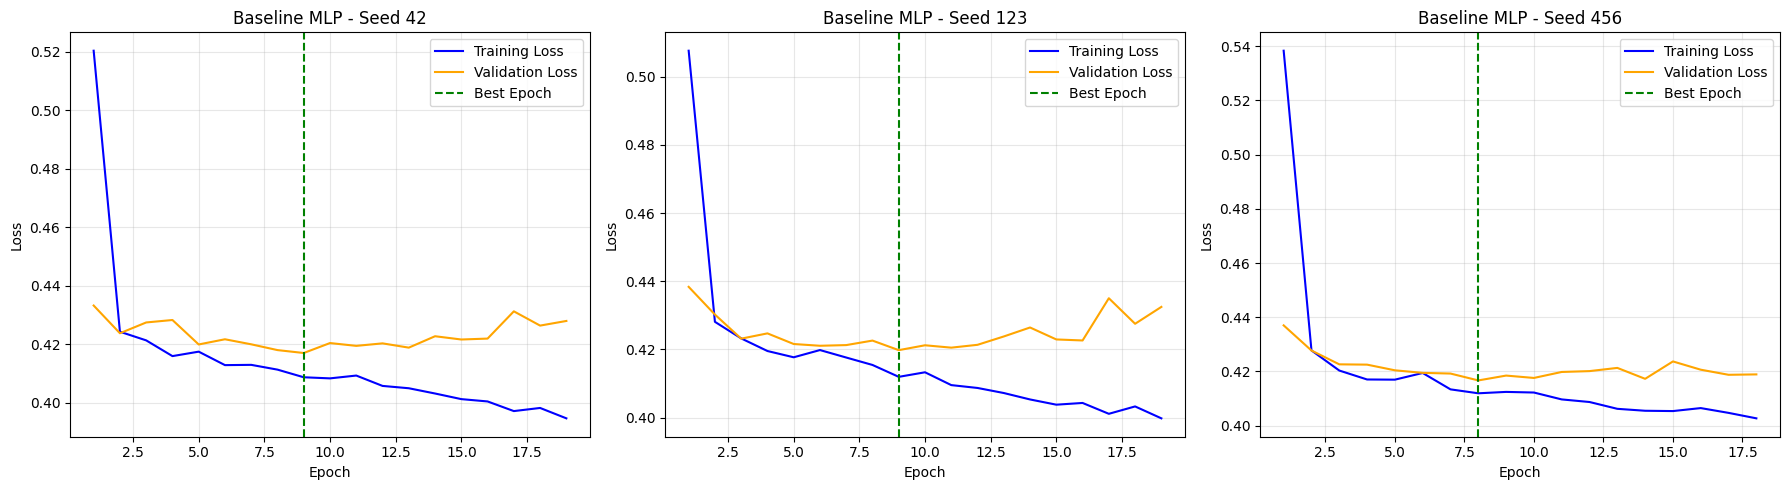

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, result in zip(axes, baseline_results):

    epochs = range(1, result["epochs_trained"] + 1)

    ax.plot(epochs, result["train_losses"],
            label="Training Loss", color="blue")

    ax.plot(epochs, result["val_losses"],
            label="Validation Loss", color="orange")

    ax.axvline(
        result["best_epoch"],
        color="green",
        linestyle="--",
        label="Best Epoch"
    )

    ax.set_title(f"Baseline MLP - Seed {result['seed']}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("baseline_loss_curves.png",
            dpi=300, bbox_inches="tight")

plt.show()

# Hyperparameter Tuning — Grid Search

In [21]:
# Hyperparameter search space
LEARNING_RATES = [0.0001, 0.0005, 0.001, 0.005]
BATCH_SIZES = [32, 64, 128]

tuning_results = []

for lr in LEARNING_RATES:
    for bs in BATCH_SIZES:

        print(f"\nLearning rate: {lr} | Batch size: {bs}")

        # Reuse existing baseline results
        if lr == LEARNING_RATE and bs == BATCH_SIZE:
            tuning_results.extend(baseline_results)
            print("Existing baseline results reused.")
            continue

        for seed in SEEDS:

            result = train_model(
                seed=seed,
                learning_rate=lr,
                batch_size=bs,
                max_epochs=MAX_EPOCHS,
                patience=PATIENCE
            )

            tuning_results.append(result)

print("\nGrid search completed!")
print("Total experiments:", len(tuning_results))


Learning rate: 0.0001 | Batch size: 32
Epoch 001 | Train Loss: 0.6396 | Val Loss: 0.5921
Epoch 002 | Train Loss: 0.5480 | Val Loss: 0.5060
Epoch 003 | Train Loss: 0.4753 | Val Loss: 0.4542
Epoch 004 | Train Loss: 0.4391 | Val Loss: 0.4355
Epoch 005 | Train Loss: 0.4276 | Val Loss: 0.4301
Epoch 006 | Train Loss: 0.4230 | Val Loss: 0.4305
Epoch 007 | Train Loss: 0.4212 | Val Loss: 0.4264
Epoch 008 | Train Loss: 0.4197 | Val Loss: 0.4253
Epoch 009 | Train Loss: 0.4184 | Val Loss: 0.4242
Epoch 010 | Train Loss: 0.4176 | Val Loss: 0.4233
Epoch 011 | Train Loss: 0.4167 | Val Loss: 0.4226
Epoch 012 | Train Loss: 0.4160 | Val Loss: 0.4220
Epoch 013 | Train Loss: 0.4155 | Val Loss: 0.4229
Epoch 014 | Train Loss: 0.4152 | Val Loss: 0.4220
Epoch 015 | Train Loss: 0.4145 | Val Loss: 0.4209
Epoch 016 | Train Loss: 0.4141 | Val Loss: 0.4219
Epoch 017 | Train Loss: 0.4133 | Val Loss: 0.4218
Epoch 018 | Train Loss: 0.4131 | Val Loss: 0.4207
Epoch 019 | Train Loss: 0.4126 | Val Loss: 0.4201
Epoch 020 

# Hyperparameter Results and Best Configuration

In [22]:
# Collect the results from all experiments
tuning_summary = pd.DataFrame([
    {
        "Seed": result["seed"],
        "Learning Rate": result["learning_rate"],
        "Batch Size": result["batch_size"],
        "Best Validation Loss": result["best_val_loss"],
        "Best Epoch": result["best_epoch"],
        "Training Time (s)": result["training_time"]
    }
    for result in tuning_results
])

# Group results by hyperparameter configuration
grid_summary = tuning_summary.groupby(
    ["Learning Rate", "Batch Size"]
).agg(
    Mean_Validation_Loss=("Best Validation Loss", "mean"),
    Std_Validation_Loss=("Best Validation Loss", "std"),
    Mean_Best_Epoch=("Best Epoch", "mean"),
    Mean_Training_Time=("Training Time (s)", "mean")
).reset_index()

# Rank configurations from best to worst
grid_summary = grid_summary.sort_values(
    "Mean_Validation_Loss"
).reset_index(drop=True)

display(grid_summary.round(6))

# Identify the best configuration
best_config = grid_summary.iloc[0]

BEST_LR = float(best_config["Learning Rate"])
BEST_BATCH_SIZE = int(best_config["Batch Size"])

print("\nBest hyperparameters:")
print("Learning rate:", BEST_LR)
print("Batch size:", BEST_BATCH_SIZE)
print("Mean validation loss:",
      round(best_config["Mean_Validation_Loss"], 6))

# Compare against the baseline
baseline_loss = baseline_summary["Best Validation Loss"].mean()
tuned_loss = best_config["Mean_Validation_Loss"]

improvement = (baseline_loss - tuned_loss) / baseline_loss * 100

print("\nBaseline validation loss:", round(baseline_loss, 6))
print("Tuned validation loss:", round(tuned_loss, 6))
print(f"Validation loss improvement: {improvement:.2f}%")

,Learning Rate,Batch Size,Mean_Validation_Loss,Std_Validation_Loss,Mean_Best_Epoch,Mean_Training_Time
0,0.0005,64,0.417172,0.001748,18.333333,4.690791
1,0.0010,32,0.417276,0.001569,6.666667,4.353104
2,0.0001,32,0.417291,0.000584,41.000000,13.594453
3,0.0001,64,0.417391,0.001529,66.333333,12.993605
4,0.0005,32,0.417435,0.001511,11.333333,5.621650
5,0.0010,128,0.417488,0.002028,11.000000,2.394568
6,0.0001,128,0.417511,0.000418,92.000000,10.694145
7,0.0005,128,0.417613,0.001259,20.000000,3.274657
8,0.0010,64,0.417844,0.001709,8.666667,3.009786
9,0.0050,32,0.418571,0.001409,6.333333,6.130341



Best hyperparameters:
Learning rate: 0.0005
Batch size: 64
Mean validation loss: 0.417172

Baseline validation loss: 0.417844
Tuned validation loss: 0.417172
Validation loss improvement: 0.16%


# Hyperparameter Tuning Heatmap

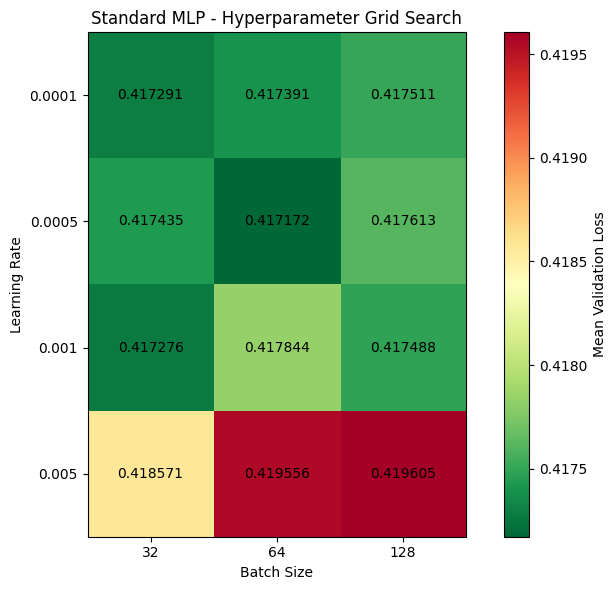

In [23]:
# Create a grid of mean validation losses
heatmap_data = grid_summary.pivot(
    index="Learning Rate",
    columns="Batch Size",
    values="Mean_Validation_Loss"
)

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.imshow(heatmap_data.values, cmap="RdYlGn_r")

ax.set_xticks(range(len(heatmap_data.columns)))
ax.set_xticklabels(heatmap_data.columns)

ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels(heatmap_data.index)

ax.set_xlabel("Batch Size")
ax.set_ylabel("Learning Rate")
ax.set_title("Standard MLP - Hyperparameter Grid Search")

# Display the loss inside each cell
for i in range(len(heatmap_data.index)):
    for j in range(len(heatmap_data.columns)):
        ax.text(
            j, i,
            f"{heatmap_data.iloc[i, j]:.6f}",
            ha="center",
            va="center",
            color="black"
        )

fig.colorbar(im, ax=ax, label="Mean Validation Loss")

plt.tight_layout()
plt.savefig("hyperparameter_heatmap.png",
            dpi=300, bbox_inches="tight")
plt.show()

# Model Evaluation Function

In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

def evaluate_model(model, loader, threshold=0.5):

    model.eval()

    all_labels = []
    all_probabilities = []

    with torch.no_grad():
        for X_batch, y_batch in loader:

            logits = model(X_batch)
            probabilities = torch.sigmoid(logits)

            all_probabilities.extend(
                probabilities.cpu().numpy().flatten()
            )

            all_labels.extend(
                y_batch.cpu().numpy().flatten()
            )

    labels = np.array(all_labels)
    probabilities = np.array(all_probabilities)

    predictions = (probabilities >= threshold).astype(int)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(labels, probabilities),
        "confusion_matrix": confusion_matrix(
            labels, predictions, labels=[0, 1]
        ),
        "labels": labels,
        "probabilities": probabilities,
        "predictions": predictions
    }

print("Evaluation function ready!")

Evaluation function ready!


# Baseline and Tuned Model Evaluation

In [25]:
# Select models with the best hyperparameter configuration
tuned_results = [
    result for result in tuning_results
    if result["learning_rate"] == BEST_LR
    and result["batch_size"] == BEST_BATCH_SIZE
]

evaluation_results = []

# Evaluate baseline and tuned models
for configuration, results in [
    ("Baseline", baseline_results),
    ("Tuned", tuned_results)
]:
    for result in results:

        metrics = evaluate_model(
            result["model"],
            test_loader,
            threshold=THRESHOLD
        )

        evaluation_results.append({
            "Configuration": configuration,
            "Seed": result["seed"],
            "Accuracy": metrics["accuracy"],
            "Precision": metrics["precision"],
            "Recall": metrics["recall"],
            "F1 Score": metrics["f1"],
            "ROC-AUC": metrics["roc_auc"],
            "Training Time (s)": result["training_time"]
        })

# Display individual results
evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

# Calculate average performance
evaluation_summary = evaluation_df.groupby(
    "Configuration"
).agg({
    "Accuracy": "mean",
    "Precision": "mean",
    "Recall": "mean",
    "F1 Score": "mean",
    "ROC-AUC": "mean",
    "Training Time (s)": "mean"
})

print("\nAverage test performance:")
display(evaluation_summary.round(4))

,Configuration,Seed,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
0,Baseline,42,0.8051,0.6943,0.4769,0.5654,0.8453,3.4038
1,Baseline,123,0.7985,0.6809,0.4555,0.5458,0.8442,2.9374
2,Baseline,456,0.8070,0.6897,0.4982,0.5785,0.8457,2.6882
3,Tuned,42,0.7975,0.6701,0.4698,0.5523,0.8461,4.7178
4,Tuned,123,0.8013,0.6732,0.4911,0.5679,0.8449,3.7535
5,Tuned,456,0.8004,0.6842,0.4626,0.5520,0.8451,5.6011



Average test performance:


,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Training Time (s)
Configuration,,,,,,
Baseline,0.8035,0.6883,0.4769,0.5633,0.8451,3.0098
Tuned,0.7997,0.6758,0.4745,0.5574,0.8454,4.6908


# Majority-Class Baseline Comparison

In [26]:
# Identify the majority class using training data
majority_class = int(y_train.mode().iloc[0])

# Predict the majority class for every test customer
majority_predictions = np.full(
    len(y_test), majority_class
)

majority_accuracy = accuracy_score(
    y_test, majority_predictions
)

majority_precision = precision_score(
    y_test, majority_predictions, zero_division=0
)

majority_recall = recall_score(
    y_test, majority_predictions, zero_division=0
)

majority_f1 = f1_score(
    y_test, majority_predictions, zero_division=0
)

print("Majority class:", majority_class)
print(f"Accuracy: {majority_accuracy:.4f}")
print(f"Precision: {majority_precision:.4f}")
print(f"Recall: {majority_recall:.4f}")
print(f"F1 Score: {majority_f1:.4f}")

print("\nAccuracy comparison:")

print(f"Majority baseline: {majority_accuracy:.4f}")

print(f"Standard MLP baseline: "
      f"{evaluation_summary.loc['Baseline', 'Accuracy']:.4f}")

print(f"Standard MLP tuned: "
      f"{evaluation_summary.loc['Tuned', 'Accuracy']:.4f}")

Majority class: 0
Accuracy: 0.7342
Precision: 0.0000
Recall: 0.0000
F1 Score: 0.0000

Accuracy comparison:
Majority baseline: 0.7342
Standard MLP baseline: 0.8035
Standard MLP tuned: 0.7997


# Confusion Matrices

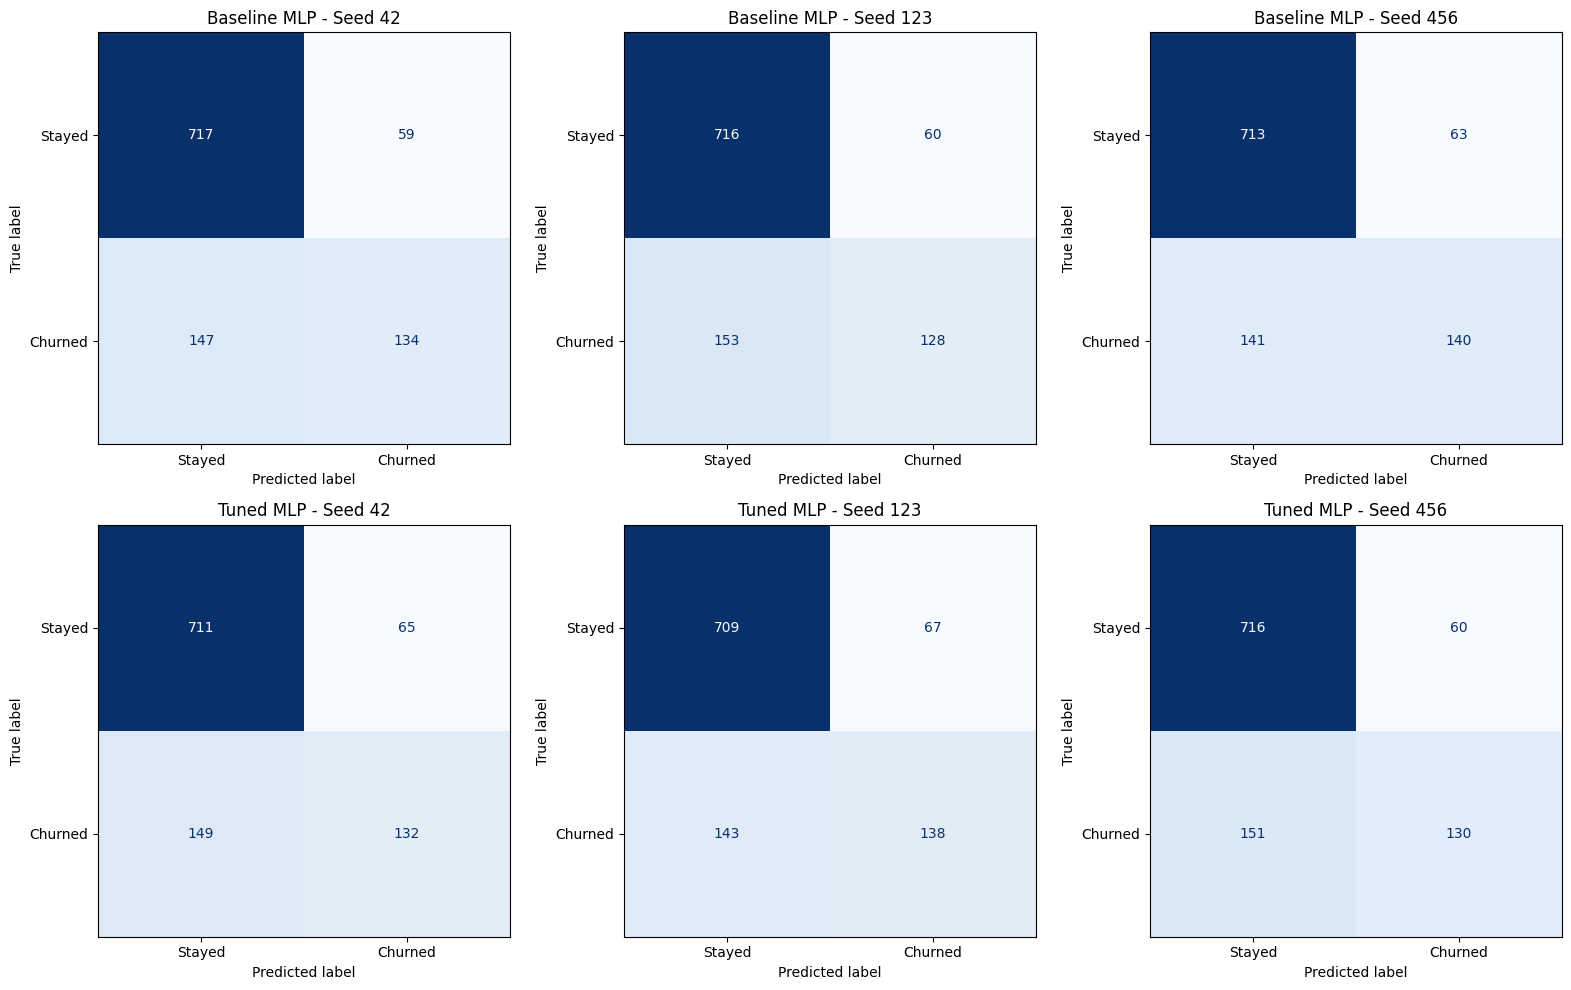

In [27]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

for row, (configuration, results) in enumerate([
    ("Baseline", baseline_results),
    ("Tuned", tuned_results)
]):
    for col, result in enumerate(results):

        metrics = evaluate_model(
            result["model"],
            test_loader,
            threshold=THRESHOLD
        )

        cm = metrics["confusion_matrix"]

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=["Stayed", "Churned"]
        )

        disp.plot(
            ax=axes[row, col],
            cmap="Blues",
            colorbar=False
        )

        axes[row, col].set_title(
            f"{configuration} MLP - Seed {result['seed']}"
        )

plt.tight_layout()

plt.savefig(
    "standard_mlp_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ROC Curves and AUC

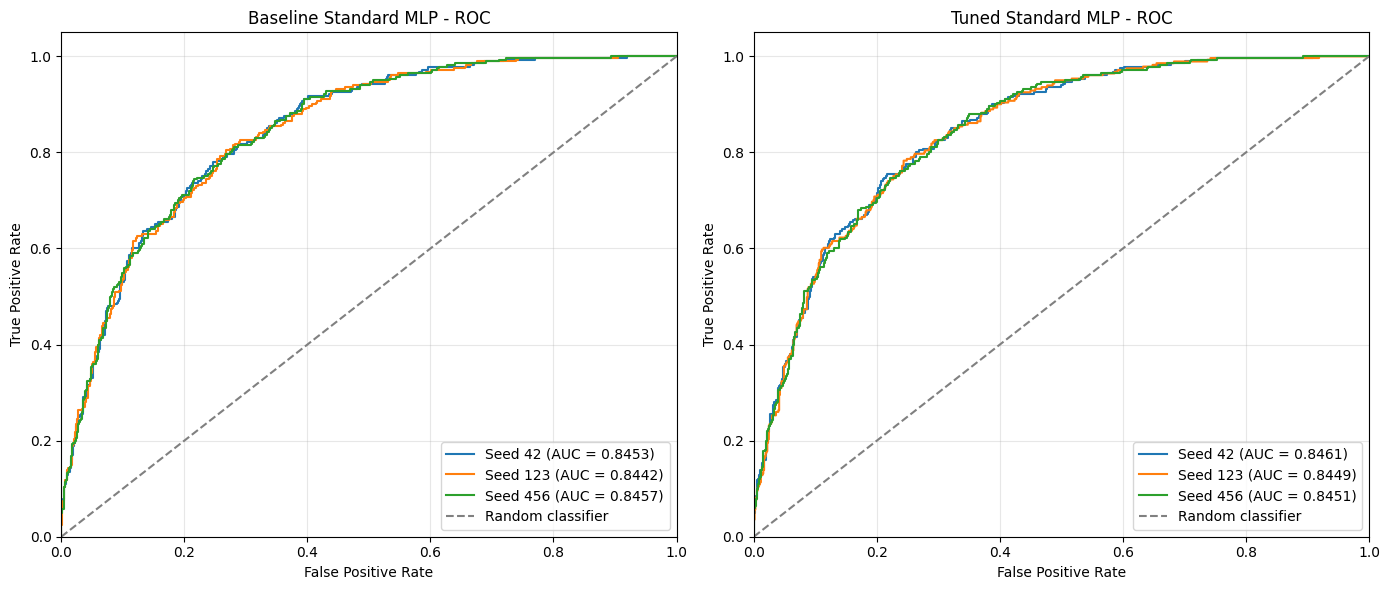

In [28]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (configuration, results) in zip(axes, [
    ("Baseline", baseline_results),
    ("Tuned", tuned_results)
]):
    for result in results:

        metrics = evaluate_model(
            result["model"],
            test_loader,
            threshold=THRESHOLD
        )

        fpr, tpr, _ = roc_curve(
            metrics["labels"],
            metrics["probabilities"]
        )

        ax.plot(
            fpr, tpr,
            label=f"Seed {result['seed']} "
                  f"(AUC = {metrics['roc_auc']:.4f})"
        )

    ax.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Random classifier"
    )

    ax.set_title(f"{configuration} Standard MLP - ROC")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.05)
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "standard_mlp_roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Baseline vs. Tuned Performance Comparison

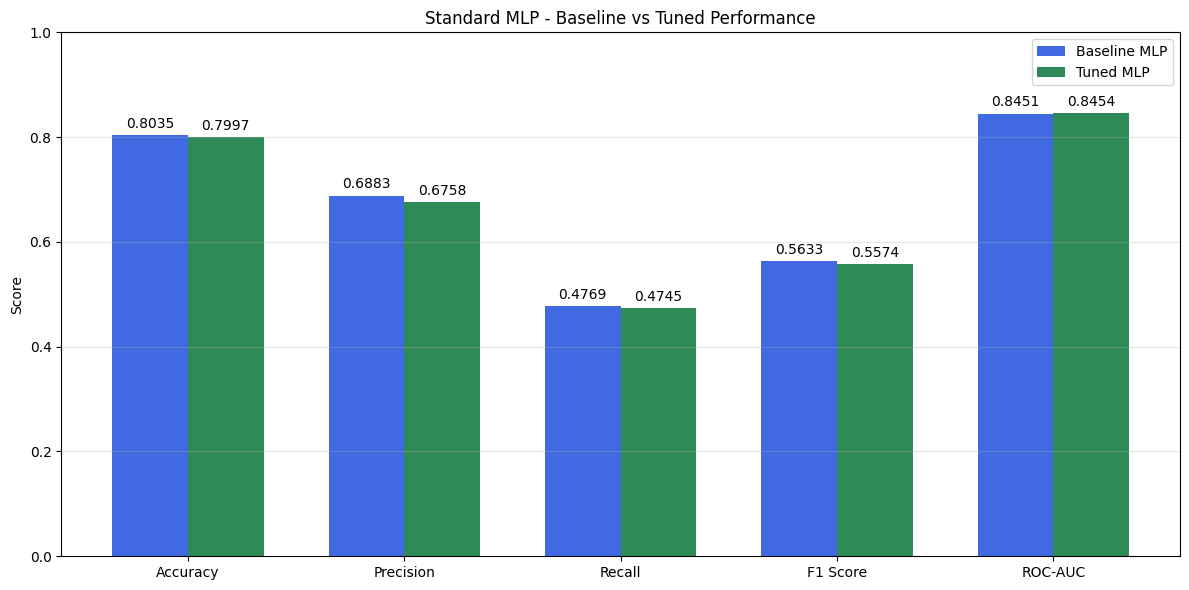

In [29]:
# Select classification metrics for comparison
metric_names = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

baseline_values = evaluation_summary.loc[
    "Baseline", metric_names
].values

tuned_values = evaluation_summary.loc[
    "Tuned", metric_names
].values

x = np.arange(len(metric_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))

bars1 = ax.bar(
    x - width / 2,
    baseline_values,
    width,
    label="Baseline MLP",
    color="royalblue"
)

bars2 = ax.bar(
    x + width / 2,
    tuned_values,
    width,
    label="Tuned MLP",
    color="seagreen"
)

ax.bar_label(bars1, fmt="%.4f", padding=3)
ax.bar_label(bars2, fmt="%.4f", padding=3)

ax.set_ylabel("Score")
ax.set_title("Standard MLP - Baseline vs Tuned Performance")
ax.set_xticks(x)
ax.set_xticklabels(metric_names)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "baseline_vs_tuned_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Tuned Model Training and Validation Loss Curves

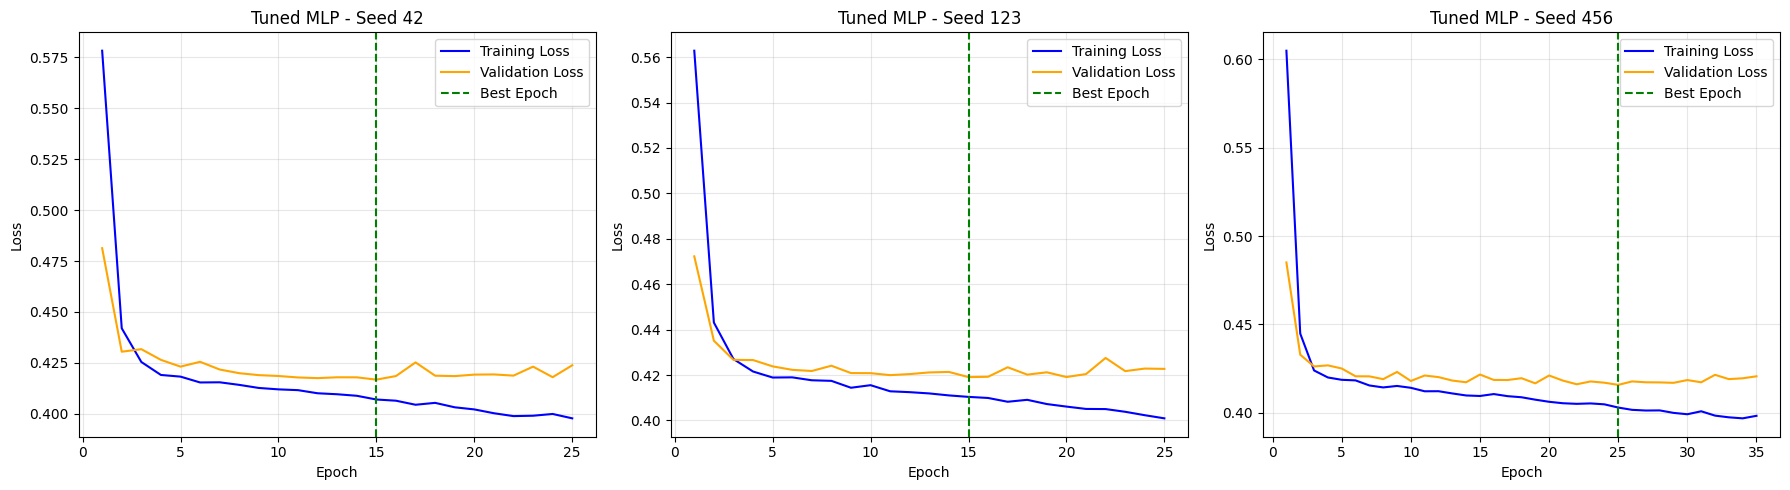

In [30]:
# Plot training and validation loss for tuned models

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, result in zip(axes, tuned_results):

    epochs = range(1, result["epochs_trained"] + 1)

    ax.plot(
        epochs,
        result["train_losses"],
        label="Training Loss",
        color="blue"
    )

    ax.plot(
        epochs,
        result["val_losses"],
        label="Validation Loss",
        color="orange"
    )

    ax.axvline(
        result["best_epoch"],
        color="green",
        linestyle="--",
        label="Best Epoch"
    )

    ax.set_title(f"Tuned MLP - Seed {result['seed']}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "tuned_loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Export Experimental Results and Predictions

In [31]:
from pathlib import Path

# Create a folder for experimental results
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)

# Save experimental tables
baseline_summary.to_csv(
    results_dir / "standard_mlp_baseline.csv",
    index=False
)

tuning_summary.to_csv(
    results_dir / "standard_mlp_tuning.csv",
    index=False
)

grid_summary.to_csv(
    results_dir / "standard_mlp_grid_search.csv",
    index=False
)

evaluation_df.to_csv(
    results_dir / "standard_mlp_test_metrics.csv",
    index=False
)

evaluation_summary.to_csv(
    results_dir / "standard_mlp_average_metrics.csv"
)

# Save predictions for every seed
for configuration, results in [
    ("baseline", baseline_results),
    ("tuned", tuned_results)
]:
    for result in results:

        metrics = evaluate_model(
            result["model"],
            test_loader,
            threshold=THRESHOLD
        )

        predictions_df = pd.DataFrame({
            "Actual": metrics["labels"].astype(int),
            "Probability": metrics["probabilities"],
            "Predicted": metrics["predictions"]
        })

        predictions_df.to_csv(
            results_dir /
            f"standard_mlp_{configuration}_seed_{result['seed']}_predictions.csv",
            index=False
        )

print("All experimental results exported successfully!")

for file in sorted(results_dir.iterdir()):
    print(file.name)

All experimental results exported successfully!
standard_mlp_average_metrics.csv
standard_mlp_baseline.csv
standard_mlp_baseline_seed_123_predictions.csv
standard_mlp_baseline_seed_42_predictions.csv
standard_mlp_baseline_seed_456_predictions.csv
standard_mlp_grid_search.csv
standard_mlp_test_metrics.csv
standard_mlp_tuned_seed_123_predictions.csv
standard_mlp_tuned_seed_42_predictions.csv
standard_mlp_tuned_seed_456_predictions.csv
standard_mlp_tuning.csv


# Save Trained Model Checkpoints

In [32]:
# Create a folder for trained models
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)

# Save baseline and tuned model checkpoints
for configuration, results in [
    ("baseline", baseline_results),
    ("tuned", tuned_results)
]:
    for result in results:

        filename = (
            f"standard_mlp_{configuration}"
            f"_seed_{result['seed']}.pth"
        )

        torch.save({
            "model_state_dict": result["model"].state_dict(),
            "seed": result["seed"],
            "learning_rate": result["learning_rate"],
            "batch_size": result["batch_size"],
            "best_epoch": result["best_epoch"],
            "best_val_loss": result["best_val_loss"],
            "threshold": THRESHOLD
        }, models_dir / filename)

        print("Saved:", filename)

print("\nAll model checkpoints saved successfully!")

Saved: standard_mlp_baseline_seed_42.pth
Saved: standard_mlp_baseline_seed_123.pth
Saved: standard_mlp_baseline_seed_456.pth
Saved: standard_mlp_tuned_seed_42.pth
Saved: standard_mlp_tuned_seed_123.pth
Saved: standard_mlp_tuned_seed_456.pth

All model checkpoints saved successfully!
